In [1]:
import pandas as pd 
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt 

In [2]:
df_training=pd.read_csv("churn-bigml-80.csv")

In [3]:
df_training.shape

(2666, 20)

In [4]:
df_training.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2666 entries, 0 to 2665
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   2666 non-null   object 
 1   Account length          2666 non-null   int64  
 2   Area code               2666 non-null   int64  
 3   International plan      2666 non-null   object 
 4   Voice mail plan         2666 non-null   object 
 5   Number vmail messages   2666 non-null   int64  
 6   Total day minutes       2666 non-null   float64
 7   Total day calls         2666 non-null   int64  
 8   Total day charge        2666 non-null   float64
 9   Total eve minutes       2666 non-null   float64
 10  Total eve calls         2666 non-null   int64  
 11  Total eve charge        2666 non-null   float64
 12  Total night minutes     2666 non-null   float64
 13  Total night calls       2666 non-null   int64  
 14  Total night charge      2666 non-null   

In [5]:
df_training.head()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [6]:
df_training.describe()

,Account length,Area code,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls
count,2666.000000,2666.000000,2666.000000,2666.00000,2666.000000,2666.000000,2666.000000,2666.000000,2666.000000,2666.000000,2666.000000,2666.000000,2666.000000,2666.000000,2666.000000,2666.000000
mean,100.620405,437.438860,8.021755,179.48162,100.310203,30.512404,200.386159,100.023631,17.033072,201.168942,100.106152,9.052689,10.237022,4.467367,2.764490,1.562641
std,39.563974,42.521018,13.612277,54.21035,19.988162,9.215733,50.951515,20.161445,4.330864,50.780323,19.418459,2.285120,2.788349,2.456195,0.752812,1.311236
min,1.000000,408.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,43.700000,33.000000,1.970000,0.000000,0.000000,0.000000,0.000000
25%,73.000000,408.000000,0.000000,143.40000,87.000000,24.380000,165.300000,87.000000,14.050000,166.925000,87.000000,7.512500,8.500000,3.000000,2.300000,1.000000
50%,100.000000,415.000000,0.000000,179.95000,101.000000,30.590000,200.900000,100.000000,17.080000,201.150000,100.000000,9.050000,10.200000,4.000000,2.750000,1.000000
75%,127.000000,510.000000,19.000000,215.90000,114.000000,36.700000,235.100000,114.000000,19.980000,236.475000,113.000000,10.640000,12.100000,6.000000,3.270000,2.000000
max,243.000000,510.000000,50.000000,350.80000,160.000000,59.640000,363.700000,170.000000,30.910000,395.000000,166.000000,17.770000,20.000000,20.000000,5.400000,9.000000


In [7]:
df_training["Churn"].value_counts(normalize=True)

Churn
False    0.854464
True     0.145536
Name: proportion, dtype: float64

In [8]:
df_training.isnull().sum()

State                     0
Account length            0
Area code                 0
International plan        0
Voice mail plan           0
Number vmail messages     0
Total day minutes         0
Total day calls           0
Total day charge          0
Total eve minutes         0
Total eve calls           0
Total eve charge          0
Total night minutes       0
Total night calls         0
Total night charge        0
Total intl minutes        0
Total intl calls          0
Total intl charge         0
Customer service calls    0
Churn                     0
dtype: int64

We can see here that there no null values in any column

In [9]:
df_training["Area code"].value_counts()

Area code
415    1318
510     679
408     669
Name: count, dtype: int64

In [10]:
print(df_training["International plan"].unique())
print(df_training['Voice mail plan'].unique())

['No' 'Yes']
['Yes' 'No']


They have only yes and no in that column

In [11]:
df_training[["Total day minutes","Total day charge",'Total eve minutes', 'Total eve charge', 
                'Total night minutes', 'Total night charge', 
                'Total intl minutes', 'Total intl charge']].corr()

,Total day minutes,Total day charge,Total eve minutes,Total eve charge,Total night minutes,Total night charge,Total intl minutes,Total intl charge
Total day minutes,1.000000,1.000000,0.003999,0.003992,0.013491,0.013464,-0.011042,-0.010934
Total day charge,1.000000,1.000000,0.004008,0.004002,0.013495,0.013468,-0.011046,-0.010938
Total eve minutes,0.003999,0.004008,1.000000,1.000000,-0.013414,-0.013450,-0.006915,-0.006947
Total eve charge,0.003992,0.004002,1.000000,1.000000,-0.013428,-0.013464,-0.006923,-0.006955
Total night minutes,0.013491,0.013495,-0.013414,-0.013428,1.000000,0.999999,-0.008607,-0.008510
Total night charge,0.013464,0.013468,-0.013450,-0.013464,0.999999,1.000000,-0.008615,-0.008517
Total intl minutes,-0.011042,-0.011046,-0.006915,-0.006923,-0.008607,-0.008615,1.000000,0.999993
Total intl charge,-0.010934,-0.010938,-0.006947,-0.006955,-0.008510,-0.008517,0.999993,1.000000


As we can see here correlation between charge and minute for day-day,eve-eve, night-night, intl-intl is almost same that is 1 which means that charge increases with respect to minute

Text(0.5, 1.0, 'Intl charge vs Intl minute')

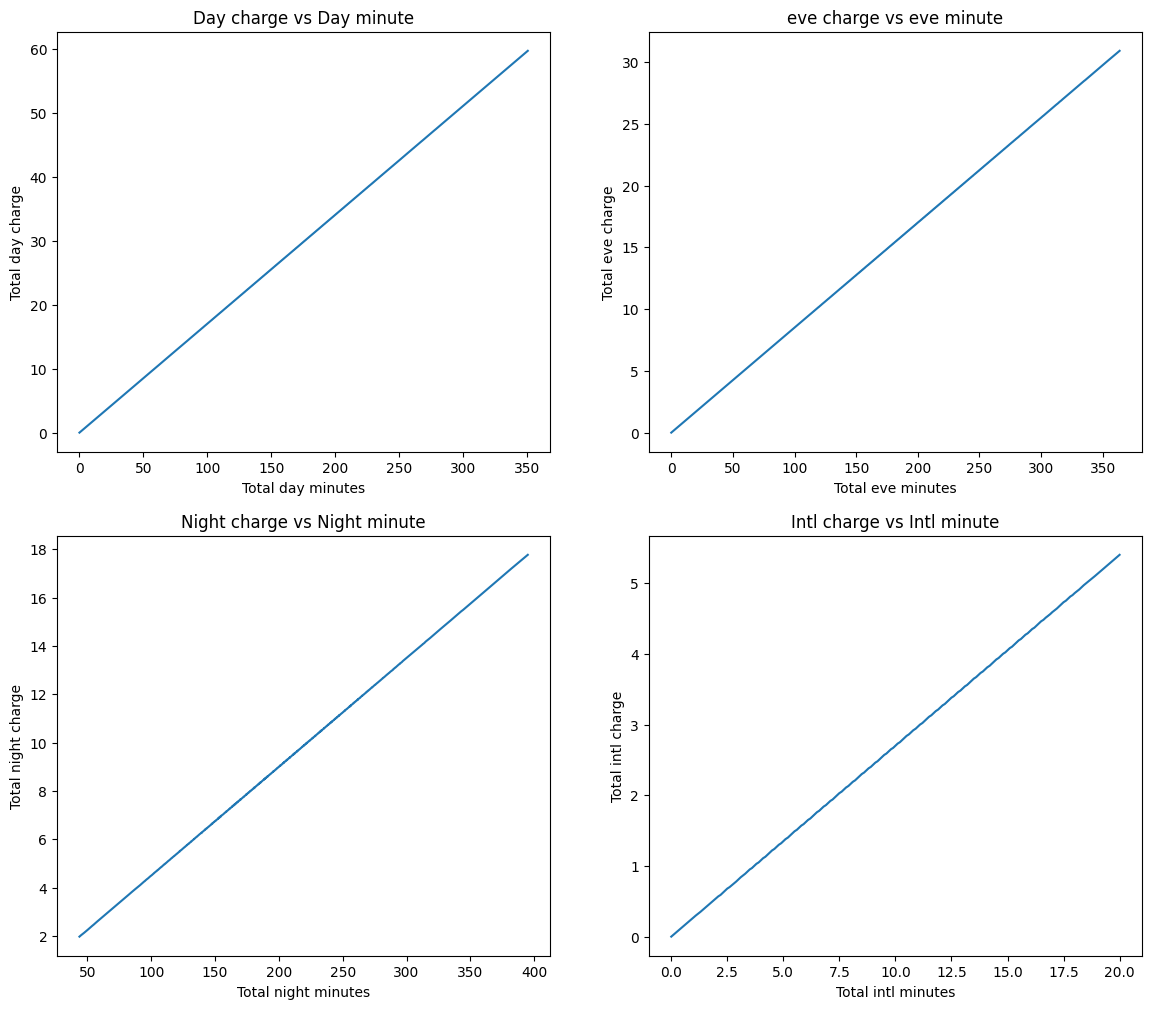

In [12]:
plt.figure(figsize=(14,12))
plt.subplot(221)
sns.lineplot(x=df_training["Total day minutes"],y=df_training["Total day charge"])
plt.title("Day charge vs Day minute")

plt.subplot(222)
sns.lineplot(x=df_training["Total eve minutes"],y=df_training["Total eve charge"])
plt.title("eve charge vs eve minute")

plt.subplot(223)
sns.lineplot(x=df_training["Total night minutes"],y=df_training["Total night charge"])
plt.title("Night charge vs Night minute")

plt.subplot(224)
sns.lineplot(x=df_training["Total intl minutes"],y=df_training["Total intl charge"])
plt.title("Intl charge vs Intl minute")

As we can see in this plot here minute and charge are dependent value 

In [13]:
df_training.head()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [14]:
col_drop=['Total day charge', 'Total eve charge', 'Total night charge', 'Total intl charge']
df_train_cleaned=df_training.drop(columns=col_drop)

We removed the upper column so that there is no multicolliearity problem

In [15]:
df_train_cleaned["Area code"]=df_train_cleaned["Area code"].astype(str)

We are converting this column from numerical to categorial for encoding

In [16]:
for col in ["International plan","Voice mail plan"]:
    df_train_cleaned[col]=df_train_cleaned[col].map({"Yes":1,"No":0})
    

We econded value for yes and no as 1, 0

In [17]:
df_train_cleaned["State"].value_counts()

State
WV    88
MN    70
NY    68
VA    67
AL    66
OH    66
WY    66
OR    62
NV    61
WI    61
MD    60
UT    60
CO    59
CT    59
MI    58
VT    57
ID    56
NC    56
TX    55
FL    54
IN    54
MT    53
OK    52
MA    52
KS    52
MO    51
DE    51
NJ    50
SC    49
SD    49
ME    49
GA    49
RI    48
MS    48
WA    48
AR    47
IL    45
DC    45
AZ    45
NE    45
HI    44
NM    44
ND    44
AK    43
KY    43
NH    43
TN    41
IA    38
PA    36
LA    35
CA    24
Name: count, dtype: int64

In [18]:
x=df_train_cleaned.drop(columns=["Churn"])
y=df_train_cleaned["Churn"]

In [19]:
num_col=x.select_dtypes(include=["int64","float64"]).columns.tolist()

In [20]:
num_col

['Account length',
 'International plan',
 'Voice mail plan',
 'Number vmail messages',
 'Total day minutes',
 'Total day calls',
 'Total eve minutes',
 'Total eve calls',
 'Total night minutes',
 'Total night calls',
 'Total intl minutes',
 'Total intl calls',
 'Customer service calls']

In [21]:
cat_col=x.select_dtypes(include=["object"]).columns.tolist()

In [22]:
cat_col

['State', 'Area code']

In [23]:
df_train_cleaned

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total eve minutes,Total eve calls,Total night minutes,Total night calls,Total intl minutes,Total intl calls,Customer service calls,Churn
0,KS,128,415,0,1,25,265.1,110,197.4,99,244.7,91,10.0,3,1,False
1,OH,107,415,0,1,26,161.6,123,195.5,103,254.4,103,13.7,3,1,False
2,NJ,137,415,0,0,0,243.4,114,121.2,110,162.6,104,12.2,5,0,False
3,OH,84,408,1,0,0,299.4,71,61.9,88,196.9,89,6.6,7,2,False
4,OK,75,415,1,0,0,166.7,113,148.3,122,186.9,121,10.1,3,3,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2661,SC,79,415,0,0,0,134.7,98,189.7,68,221.4,128,11.8,5,2,False
2662,AZ,192,415,0,1,36,156.2,77,215.5,126,279.1,83,9.9,6,2,False
2663,WV,68,415,0,0,0,231.1,57,153.4,55,191.3,123,9.6,4,3,False
2664,RI,28,510,0,0,0,180.8,109,288.8,58,191.9,91,14.1,6,2,False


In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler,OneHotEncoder

In [25]:
ct=ColumnTransformer([
                    ("num",StandardScaler(),num_col),
                    ("cat",OneHotEncoder(drop="first",sparse_output=False),cat_col)
    
])